# What predicts a Ballon d'Or? Ten-edition experiments (v2)

Results of Stages 0-6 of `ballon_dor_experiments_spec.md`, read from `results/v2/`. Nothing is recomputed here, so the notebook runs in seconds; the code that produced each file is in `src/model/` (`run_bridge.py`, `run_stage3.py`, `run_stage4_research.py`, `run_stage4_jury.py`).

**2026 is held out.** No 2026 result appears below; section 10 is the locked forecast only. Decisions taken along the way are in `results/v2/deviations.md`.

Contents: 1 Data and bridge to v1 · 2 Model comparison (Table 1) · 3 What explains the vote · 4 Fame replication · 5 Post-window information · 6 Tournament check · 7 Jury experiments · 8 Odds baseline · 9 Robustness · 10 The 2026 forecast

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = Path('results/v2')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEASON4 = [2022, 2023, 2024, 2025]
def fmt(df, d=3):
    return df.style.format(precision=d, na_rep='')

## 1. Data and bridge to v1

The expanded file has 300 rows (10 editions × 30); 270 are labelled (2016-19, 2021-25). Point sums equal jurors × points per ballot in every labelled edition.

In [2]:
t1 = pd.read_csv('data/v2/player_snapshot_t1.csv')
facts = t1.groupby('edition').agg(format=('eligibility_format','first'), picks=('ballot_picks','first'), jurors=('jurors_voted','first'),
                                  points=('bdo_points','sum'), zero_point_nominees=('bdo_points', lambda s: int((s==0).sum())))
facts.loc[2026, ['points','zero_point_nominees']] = np.nan   # forecast edition: targets are null by design
facts

,format,picks,jurors,points,zero_point_nominees
edition,,,,,
2016,calendar_year,3,173.0,1557.0,11.0
2017,calendar_year,5,176.0,2816.0,2.0
2018,calendar_year,5,180.0,2880.0,2.0
2019,calendar_year,5,176.0,2816.0,3.0
2021,calendar_year,5,170.0,2720.0,2.0
2022,season,5,93.0,1488.0,11.0
2023,season,5,92.0,1472.0,5.0
2024,season,10,99.0,6633.0,2.0
2025,season,10,100.0,6700.0,0.0


**Bridge run.** The v1 design (v1 features) run on the 2022-26 rows of the expanded file. `as_revised` is the file as delivered; `v1_columns_restored` puts back the three columns the dataset revised after v1. Both reproduce v1.

In [3]:
b = pd.read_csv(R/'bridge_vs_v1.csv')
ll = b[b.metric=='heldout_ll'].pivot(index='model', columns='variant', values=['mean_bridge','mean_v1']).round(4)
print('Largest absolute difference from v1 over all models and metrics:', f"{b.difference.abs().max():.1e}")
ll

Largest absolute difference from v1 over all models and metrics: 6.3e-14


mean_bridge                        mean_v1                    
variant  as_revised v1_columns_restored as_revised v1_columns_restored
model                                                                 
B0          -2.6417             -2.6417    -2.6417             -2.6417
B1          -2.5967             -2.5967    -2.5967             -2.5967
B2          -2.6054             -2.6054    -2.6054             -2.6054
M1          -2.3348             -2.3348    -2.3348             -2.3348
M1-G        -2.3362             -2.3362    -2.3362             -2.3362
M2          -2.3758             -2.3758    -2.3758             -2.3758
U0          -2.7517             -2.7517    -2.7517             -2.7517
X1          -2.3661             -2.3661    -2.3661             -2.3661

In [4]:
pd.read_csv(R/'bridge_revised_columns.csv')

,edition,player_name,column,v1_value,expanded_value
0,2022,Cristiano Ronaldo,career_bdo_podiums_before,9,12
1,2023,Lionel Messi,career_bdo_podiums_before,10,13
2,2026,Lionel Messi,career_bdo_podiums_before,11,14
3,2026,Lionel Messi,club_trophies_n,2,1
4,2026,Lionel Messi,won_domestic_cup,1,0


## 2. Model comparison (Table 1)

Leave-one-edition-out over nine editions, nested inner leave-one-edition-out for the ridge penalty. Primary metric: held-out Plackett-Luce log-likelihood per voted player (higher is better). Intervals: 90% within-edition bootstrap (1,000 draws).

In [5]:
s = pd.read_csv(R/'metrics_summary.csv')
order = ['B0','B1','X1','L1','O1','D1','M1','M1-G','M1-F']
def cell(row, metric, sub):
    m = s[(s.model==row)&(s.metric==metric)].iloc[0]
    mean = m['mean_all'] if sub=='all' else m['mean_2022_25']
    lo, hi = m[f'lo90_{sub if sub=="all" else "season4"}'], m[f'hi90_{sub if sub=="all" else "season4"}']
    return f"{mean:.3f}" if pd.isna(lo) else f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
metrics = ['heldout_ll','winner_rank','top3_overlap','top10_acc','ndcg10']
def table1(sub):
    return pd.DataFrame({mt: [cell(m, mt, sub) for m in order] for mt in metrics}, index=order)
print('Nine-fold means'); display(table1('all'))
print('Same models, 2022-2025 folds only (directly comparable with v1)'); display(table1('season4'))

Nine-fold means


,heldout_ll,winner_rank,top3_overlap,top10_acc,ndcg10
B0,"-2.624 [-2.723, -2.591]",4.111,"1.111 [1.000, 1.889]","0.578 [0.500, 0.656]","0.707 [0.618, 0.782]"
B1,"-2.541 [-2.647, -2.504]",2.000,"2.000 [1.333, 2.222]","0.722 [0.622, 0.767]","0.877 [0.797, 0.908]"
X1,"-2.350 [-2.482, -2.325]",2.556,"1.889 [1.333, 2.222]","0.711 [0.633, 0.778]","0.848 [0.766, 0.894]"
L1,"-2.419 [-2.552, -2.392]",1.889,"2.000 [1.556, 2.333]","0.667 [0.589, 0.733]","0.854 [0.780, 0.900]"
O1,"-2.349 [-2.493, -2.318]",2.000,"2.000 [1.439, 2.228]","0.689 [0.622, 0.767]","0.881 [0.801, 0.914]"
D1,"-2.644 [-2.759, -2.599]",1.778,"1.333 [1.000, 1.889]","0.578 [0.456, 0.611]","0.744 [0.601, 0.776]"
M1,"-2.348 [-2.493, -2.317]",2.000,"2.111 [1.444, 2.333]","0.733 [0.633, 0.778]","0.895 [0.821, 0.924]"
M1-G,"-2.349 [-2.494, -2.317]",2.000,"2.111 [1.444, 2.333]","0.722 [0.633, 0.778]","0.893 [0.820, 0.924]"
M1-F,"-2.344 [-2.486, -2.317]",2.000,"2.111 [1.444, 2.333]","0.722 [0.644, 0.778]","0.885 [0.824, 0.920]"


Same models, 2022-2025 folds only (directly comparable with v1)


,heldout_ll,winner_rank,top3_overlap,top10_acc,ndcg10
B0,"-2.610 [-2.741, -2.566]",6.750,"0.750 [0.500, 1.750]","0.625 [0.500, 0.700]","0.614 [0.508, 0.744]"
B1,"-2.466 [-2.612, -2.425]",2.500,"2.000 [1.000, 2.262]","0.775 [0.625, 0.825]","0.863 [0.774, 0.918]"
X1,"-2.284 [-2.458, -2.230]",3.250,"2.000 [1.250, 2.500]","0.775 [0.650, 0.850]","0.860 [0.777, 0.939]"
L1,"-2.441 [-2.621, -2.371]",2.750,"1.500 [1.000, 2.250]","0.750 [0.575, 0.800]","0.817 [0.720, 0.888]"
O1,"-2.277 [-2.478, -2.220]",2.500,"2.000 [1.000, 2.500]","0.775 [0.650, 0.850]","0.893 [0.802, 0.938]"
D1,"-2.710 [-2.892, -2.600]",2.000,"0.750 [0.500, 1.750]","0.575 [0.425, 0.650]","0.684 [0.501, 0.764]"
M1,"-2.275 [-2.468, -2.225]",2.500,"2.250 [1.250, 2.500]","0.800 [0.650, 0.850]","0.902 [0.817, 0.944]"
M1-G,"-2.275 [-2.468, -2.225]",2.500,"2.250 [1.250, 2.500]","0.800 [0.650, 0.850]","0.902 [0.817, 0.944]"
M1-F,"-2.270 [-2.445, -2.238]",2.500,"2.250 [1.250, 2.500]","0.800 [0.675, 0.851]","0.885 [0.830, 0.942]"


In [6]:
folds = [2016,2017,2018,2019,2021,2022,2023,2024,2025]
ll = s[s.metric=='heldout_ll'].set_index('model')
cols = ['mean_all','mean_2022_25'] + [f'fold_{f}' for f in folds]
fmt(ll[cols].sort_values('mean_all', ascending=False, na_position='last'))

,mean_all,mean_2022_25,fold_2016,fold_2017,fold_2018,fold_2019,fold_2021,fold_2022,fold_2023,fold_2024,fold_2025
model,,,,,,,,,,,
M1-F,-2.344,-2.270,-2.601,-2.191,-2.460,-2.204,-2.560,-2.516,-2.293,-2.095,-2.176
M1,-2.348,-2.275,-2.609,-2.224,-2.435,-2.235,-2.525,-2.556,-2.273,-2.105,-2.168
M1-G,-2.349,-2.275,-2.610,-2.224,-2.443,-2.234,-2.525,-2.555,-2.273,-2.105,-2.168
O1,-2.349,-2.277,-2.574,-2.256,-2.493,-2.267,-2.441,-2.591,-2.268,-2.117,-2.131
X1,-2.350,-2.284,-2.691,-2.211,-2.395,-2.274,-2.441,-2.485,-2.292,-2.095,-2.264
L1,-2.419,-2.441,-2.496,-2.231,-2.458,-2.317,-2.504,-2.640,-2.402,-2.420,-2.303
B2,-2.529,-2.502,-2.661,-2.407,-2.683,-2.456,-2.547,-2.761,-2.510,-2.411,-2.327
B1,-2.541,-2.466,-2.956,-2.361,-2.599,-2.444,-2.640,-2.903,-2.494,-2.222,-2.247
B0,-2.624,-2.610,-3.063,-2.411,-2.648,-2.564,-2.486,-2.810,-2.569,-2.420,-2.642


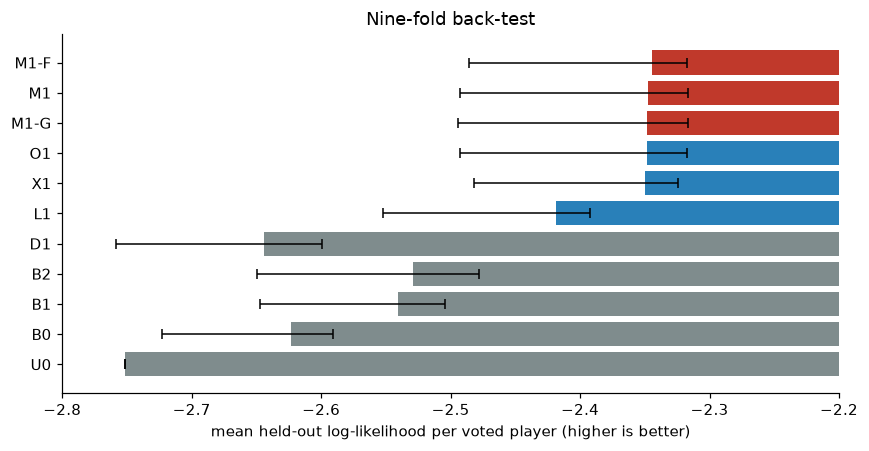

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
show = ['U0','B0','B1','B2','D1','L1','X1','O1','M1-G','M1','M1-F']
vals = ll.loc[show, 'mean_all']
lo = s[(s.metric=='heldout_ll')].set_index('model')['lo90_all']; hi = s[(s.metric=='heldout_ll')].set_index('model')['hi90_all']
y = np.arange(len(show))
ax.barh(y, vals, color=['#7f8c8d' if m in ('U0','B0','B1','B2','D1') else '#c0392b' if m in ('M1','M1-G','M1-F') else '#2980b9' for m in show])
ax.errorbar(vals, y, xerr=[(vals-lo.loc[show]).fillna(0), (hi.loc[show]-vals).fillna(0)], fmt='none', ecolor='black', capsize=3, lw=1)
ax.set_yticks(y, show); ax.set_xlim(-2.8, -2.2); ax.set_xlabel('mean held-out log-likelihood per voted player (higher is better)')
ax.set_title('Nine-fold back-test'); plt.tight_layout(); plt.show()

**Paired differences against M1** (same resampled players for both models):

In [8]:
p = pd.read_csv(R/'paired_vs_M1.csv'); fmt(p[p.subset=='all'].drop(columns=['subset','vs']).set_index('model'))

,mean_diff,lo90,hi90,share_better
model,,,,
B0,-0.253,-0.326,-0.179,0.000
B1,-0.173,-0.234,-0.112,0.000
B2,-0.158,-0.232,-0.085,0.000
X1,0.002,-0.054,0.060,0.518
L1,-0.066,-0.121,-0.011,0.016
O1,-0.003,-0.027,0.024,0.424
D1,-0.274,-0.352,-0.194,0.000
M1-G,-0.001,-0.001,0.000,0.062
M1-F,0.003,-0.013,0.021,0.620


**What the extra editions buy** (2022-2025 folds): v1 features trained on 3 editions, v2 features trained on the same 3, v2 features trained on the 8 others.

In [9]:
mf = pd.read_csv(R/'metrics_by_fold.csv')
m = mf[(mf.metric=='heldout_ll')]
v1 = pd.read_csv(R/'bridge_vs_v1.csv'); v1m = v1[(v1.metric=='heldout_ll')&(v1.model=='M1')&(v1.variant=='as_revised')].mean_v1.iloc[0]
rows = {'v1 features, 3 training editions (v1)': v1m,
        'v2 features, 3 training editions (M1-season4)': m[(m.model=='M1-season4')].value.mean(),
        'v2 features, 8 training editions (M1, 2022-25 folds)': m[(m.model=='M1')&(m.fold.isin(SEASON4))].value.mean()}
pd.Series(rows, name='mean held-out log-likelihood').round(4).to_frame()

,mean held-out log-likelihood
"v1 features, 3 training editions (v1)",-2.3348
"v2 features, 3 training editions (M1-season4)",-2.2773
"v2 features, 8 training editions (M1, 2022-25 folds)",-2.2753


**Selection (spec 5.4):** the simplest Plackett-Luce model within 0.02 of the best one is published, so **M1** is published and O1 is reported alongside. Back-test coefficients of M1 (mean over the nine fold fits):

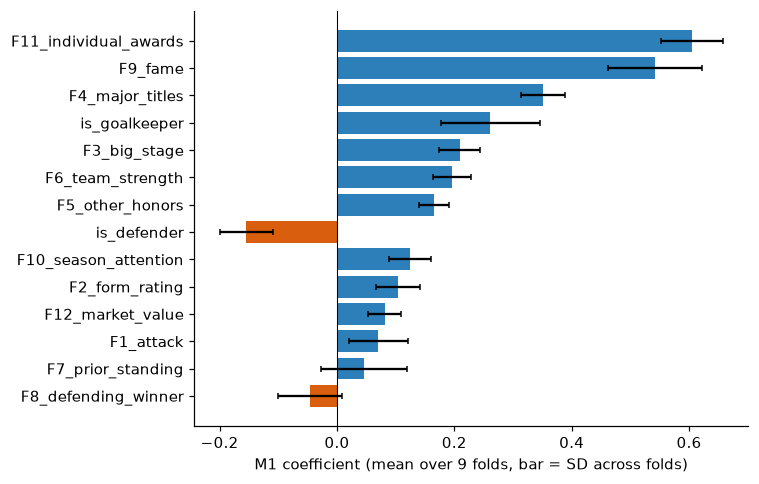

,mean_beta,sd_across_folds,same_sign_folds
feature,,,
F11_individual_awards,0.605,0.053,9
F9_fame,0.542,0.080,9
F4_major_titles,0.352,0.037,9
is_goalkeeper,0.262,0.084,9
F3_big_stage,0.209,0.036,9
F6_team_strength,0.196,0.033,9
F5_other_honors,0.165,0.026,9
is_defender,-0.154,0.046,9
F10_season_attention,0.125,0.035,9


In [10]:
cf = pd.read_csv(R/'coefficients_by_fold.csv'); cf = cf[cf.model=='M1']
w = cf.pivot(index='feature', columns='fold', values='beta')
tab = pd.DataFrame({'mean_beta': w.mean(axis=1), 'sd_across_folds': w.std(axis=1, ddof=1),
                    'same_sign_folds': w.apply(lambda r: int((np.sign(r)==np.sign(r.mean())).sum()), axis=1)})
tab = tab.reindex(tab.mean_beta.abs().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(tab.index[::-1], tab.mean_beta[::-1], xerr=tab.sd_across_folds[::-1], color=np.where(tab.mean_beta[::-1]>0, '#2c7fb8', '#d95f0e'), capsize=2)
ax.axvline(0, color='black', lw=.7); ax.set_xlabel('M1 coefficient (mean over 9 folds, bar = SD across folds)'); plt.tight_layout(); plt.show()
fmt(tab)

## 3. What explains the vote

### Variance shares
Out-of-sample (leave-one-edition-out) R² of the within-edition points percentile, split across feature blocks by Shapley values; 90% intervals from 300 bootstrap draws.

In [11]:
vs = pd.read_csv(R/'variance_shares.csv')
print(f"Total out-of-sample R2 = {vs.total_oos_r2.iloc[0]:.2f}  (90% interval {vs.total_oos_r2_lo90.iloc[0]:.2f}-{vs.total_oos_r2_hi90.iloc[0]:.2f})")
fmt(vs.drop(columns=['total_oos_r2','total_oos_r2_lo90','total_oos_r2_hi90']).set_index('block'))

Total out-of-sample R2 = 0.50  (90% interval 0.40-0.56)


,r2_alone,share,share_lo90,share_hi90,unique_r2
block,,,,,
Trophies and team,0.143,0.254,0.148,0.367,0.109
Fame and attention,0.278,0.225,0.133,0.318,0.041
Individual awards,0.235,0.214,0.138,0.321,0.052
Big stage,0.208,0.114,0.068,0.178,-0.001
Season output,0.177,0.087,0.020,0.144,-0.004
Prior standing,0.165,0.082,0.032,0.136,-0.006
Position,0.038,0.020,-0.011,0.061,0.002
Market value,0.032,0.004,-0.028,0.031,-0.004


### Ablations
M1 refitted without one block at a time. A block matters if dropping it worsens held-out log-likelihood in at least 6 of 9 folds (the rule counts folds, not size).

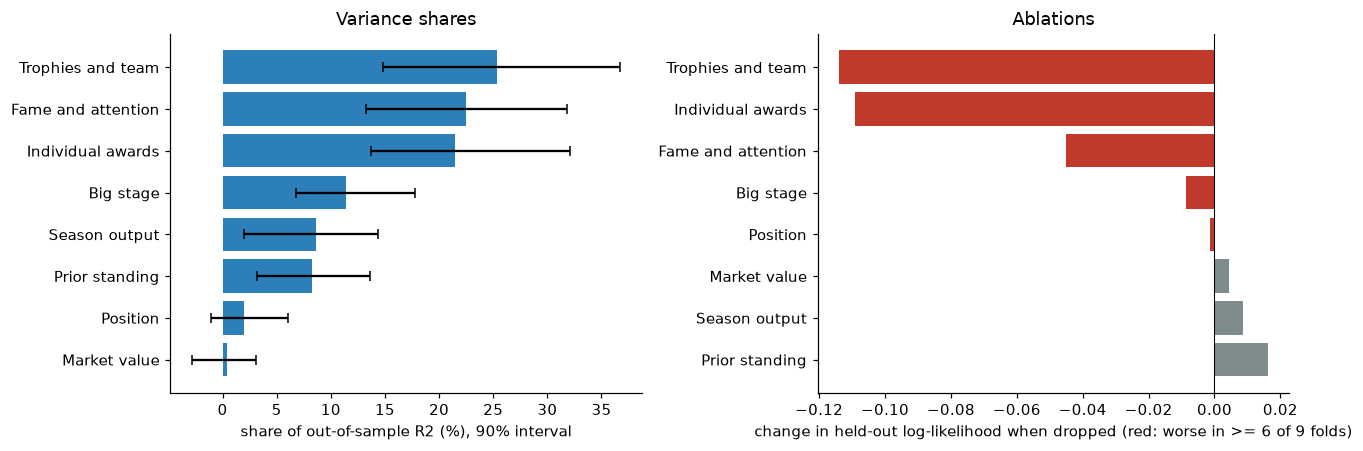

,mean_delta_ll,folds_worse,matters,mean_delta_winner_rank
block,,,,
Trophies and team,-0.114,8,True,0.444
Individual awards,-0.109,8,True,0.556
Fame and attention,-0.045,7,True,-0.111
Big stage,-0.009,7,True,0.000
Position,-0.001,6,True,0.000
Market value,0.005,5,False,0.000
Season output,0.009,2,False,0.222
Prior standing,0.016,1,False,0.111


In [12]:
ab = pd.read_csv(R/'ablations.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
o = vs.iloc[::-1]
axes[0].barh(o.block, o.share*100, xerr=[(o.share-o.share_lo90)*100, (o.share_hi90-o.share)*100], capsize=3, color='#2c7fb8')
axes[0].set_xlabel('share of out-of-sample R2 (%), 90% interval'); axes[0].set_title('Variance shares')
a = ab.iloc[::-1]
axes[1].barh(a.block, a.mean_delta_ll, color=np.where(a.matters, '#c0392b', '#7f8c8d')); axes[1].axvline(0, color='black', lw=.7)
axes[1].set_xlabel('change in held-out log-likelihood when dropped (red: worse in >= 6 of 9 folds)'); axes[1].set_title('Ablations')
plt.tight_layout(); plt.show()
fmt(ab[['block','mean_delta_ll','folds_worse','matters','mean_delta_winner_rank']].set_index('block'))

### TreeSHAP on L1 (supplement)
In-sample, all nine labelled editions; descriptive only.

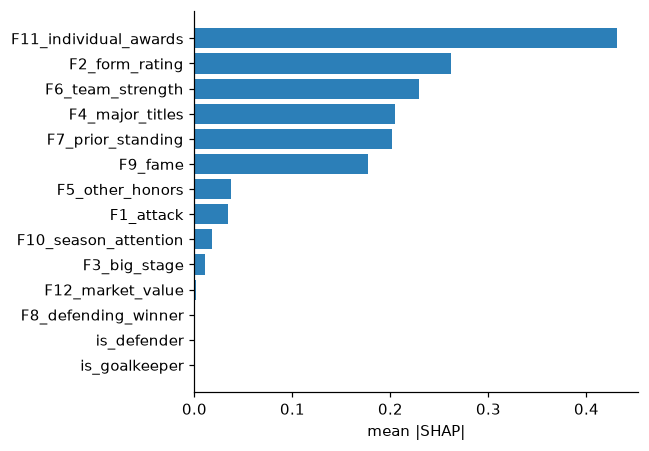

In [13]:
sh = pd.read_csv(R/'shap_L1.csv')
fig, ax = plt.subplots(figsize=(6, 4.2)); ax.barh(sh.feature[::-1], sh.mean_abs_shap[::-1], color='#2c7fb8'); ax.set_xlabel('mean |SHAP|'); plt.tight_layout(); plt.show()

## 4. The fame finding, replicated

v1: among players whose football alone pointed to a top-10 finish, those with at least the expected attention finished about 4.9th and the rest about 10.8th. Here: a football-only Plackett-Luce model (leave-one-edition-out) picks each edition's predicted top 10; players are split by `fame` residualised on football features in the training fold. Permutation p-values shuffle the split within edition (10,000 times).

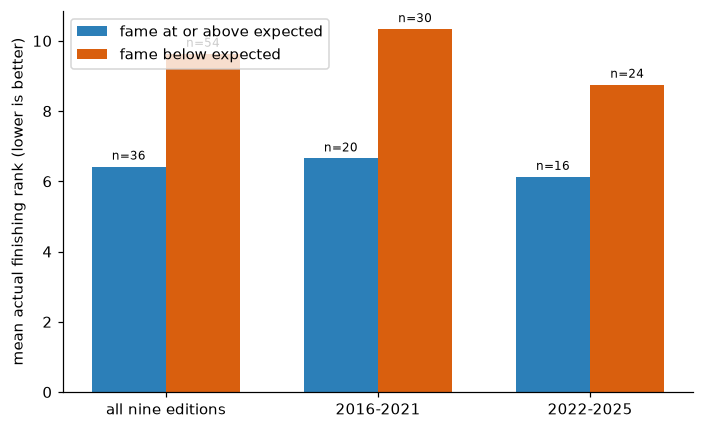

In [14]:
fm = pd.read_csv(R/'fame_test.csv')
eras = fm.era.unique()
fig, ax = plt.subplots(figsize=(6.5, 4)); w = .35
for i, e in enumerate(eras):
    hi = fm[(fm.era==e)&(fm.group=='fame at or above expected')].iloc[0]; lo = fm[(fm.era==e)&(fm.group=='fame below expected')].iloc[0]
    ax.bar(i-w/2, hi.mean_actual_rank, w, color='#2c7fb8', label='fame at or above expected' if i==0 else None)
    ax.bar(i+w/2, lo.mean_actual_rank, w, color='#d95f0e', label='fame below expected' if i==0 else None)
    ax.text(i-w/2, hi.mean_actual_rank+.2, f"n={hi.n}", ha='center', fontsize=8); ax.text(i+w/2, lo.mean_actual_rank+.2, f"n={lo.n}", ha='center', fontsize=8)
ax.set_xticks(range(len(eras)), eras); ax.set_ylabel('mean actual finishing rank (lower is better)'); ax.legend(); plt.tight_layout(); plt.show()
fmt(fm.set_index(['era','group']))

**Pre-registered hypothesis:** `season_attention × first_time` (expected positive), final M1 fit on all nine editions, 90% intervals.

In [15]:
fmt(pd.read_csv(R/'attention_first_time.csv').drop(columns=['model','editions']).set_index('feature'))

,beta,se_laplace,laplace_lo90,laplace_hi90,bootstrap_lo90,bootstrap_hi90,lambda
feature,,,,,,,
F10_season_attention,0.072,0.129,-0.141,0.285,-0.060,0.199,10.000
season_attention_x_first_time,0.061,0.136,-0.162,0.285,-0.054,0.208,10.000


## 5. Does post-window information matter? (M2 vs M1, 2022-2025)

Four folds, T2 snapshot. **Caveat:** `post_npga_p90_opp_adj` is non-null for only 1 of 30 players in 2025, so P1 is constant in the 2025 fold (as in v1).

In [16]:
pw = pd.read_csv(R/'post_window_test.csv').set_index('fold')
print(f"Mean M2 minus M1: {pw.m2_minus_m1.mean():+.3f}; M2 better in {(pw.m2_minus_m1>0).sum()} of 4 folds")
fmt(pw)

Mean M2 minus M1: -0.028; M2 better in 2 of 4 folds


,M1,M2,m2_minus_m1,P1_post_form,P2_post_attention,P3_final_spike
fold,,,,,,
2022,-2.438,-2.430,0.008,0.086,0.043,0.014
2023,-2.328,-2.321,0.007,0.087,-0.019,0.060
2024,-2.083,-2.186,-0.103,0.392,-0.105,-0.095
2025,-2.259,-2.285,-0.026,0.135,-0.112,0.097


## 6. World Cup and tournament check

Players who played a World Cup, Euro or Copa in the tournament editions (2016, 2018, 2019, 2021, 2023, 2024). Residual = actual rank minus predicted rank; negative means the player finished better than predicted.

In [17]:
tc = pd.read_csv(R/'tournament_check.csv'); fmt(tc.set_index(['model','subset']), 2)

In [18]:
fmt(pd.read_csv(R/'tournament_coefficients.csv').drop(columns=['se_laplace','lambda']).set_index(['model','feature']))

## 7. Jury experiments

Ballot-level Plackett-Luce on 37,770 votes (1,259 ballots, 2016-2025): one strength per player-edition plus juror terms `home` (juror nation = player nationality), `confed` (same confederation, excluding home) and `league` (juror nation = player's league country). Fitted on 2022-2025 alone, it reproduces v1 exactly.

In [19]:
print(pd.read_csv(R/'jury_v1_reproduction.csv').round(4).to_string(index=False))

indicator  v1_beta  v2_beta  v1_boot_lo90  v2_boot_lo90  v1_boot_hi90  v2_boot_hi90
     home   2.3110   2.3110        1.8797        1.8797        2.8043        2.8043
   confed   0.3663   0.3663        0.2437        0.2437        0.4881        0.4881
   league   0.4781   0.4781        0.0280        0.0280        0.9464        0.9464


### 7.1 Home bias across the 2022 reform (jury cut from ~175 to 100 nations)

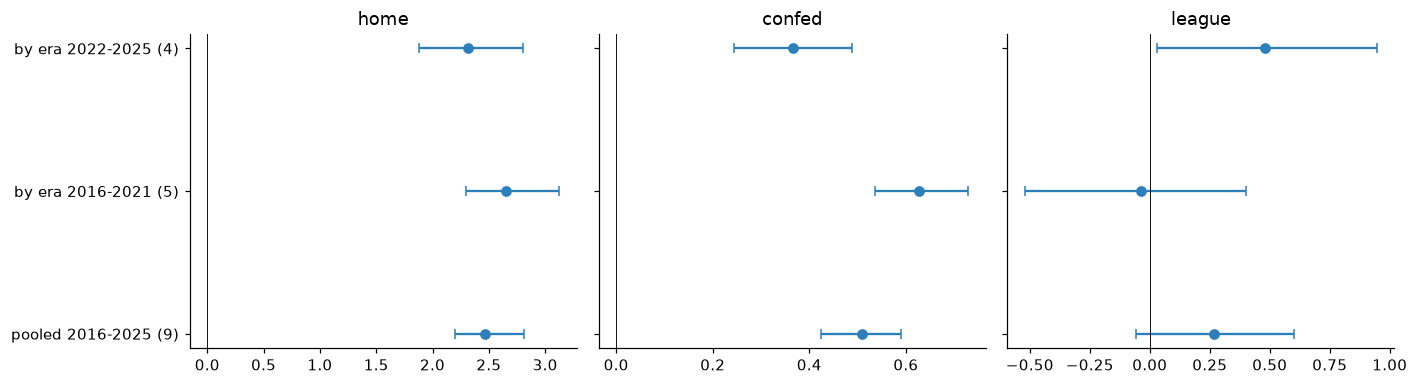

In [20]:
j = pd.read_csv(R/'jury_bias_by_era.csv')
sel = j[j.spec.isin(['pooled','by era'])].copy()
sel['label'] = sel.spec + ' ' + sel.editions
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, ind in zip(axes, ['home','confed','league']):
    d = sel[sel.indicator==ind].reset_index(drop=True)
    ax.errorbar(d.beta, range(len(d)), xerr=[d.beta-d.boot_lo90, d.boot_hi90-d.beta], fmt='o', capsize=3, color='#2c7fb8')
    ax.axvline(0, color='black', lw=.6); ax.set_title(ind); ax.set_yticks(range(len(d)), d.label)
plt.tight_layout(); plt.show()
fmt(j[j.spec!='by edition'][['spec','editions','indicator','beta','boot_lo90','boot_hi90','n_pairs']].set_index(['spec','editions','indicator']))

The `era interaction` rows test whether home bias changed: `home_x_era2022` is the change after the reform, `home (2022-2025 jury)` the resulting home effect after it.

**Home coefficient by edition** (200 bootstrap draws):

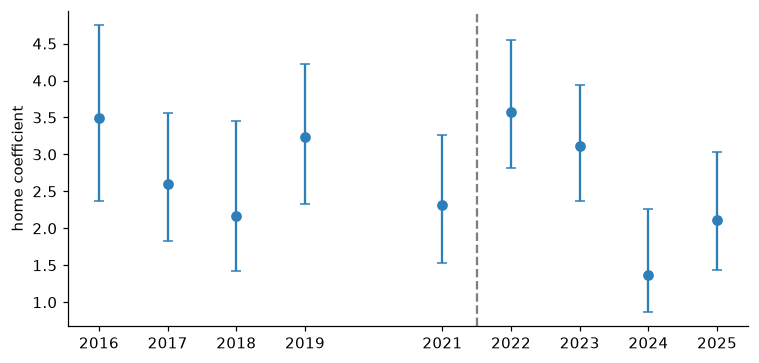

In [21]:
be = j[(j.spec=='by edition')&(j.indicator=='home')]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.errorbar(be.editions.astype(int), be.beta, yerr=[be.beta-be.boot_lo90, be.boot_hi90-be.beta], fmt='o', capsize=3, color='#2c7fb8')
ax.axvline(2021.5, color='grey', ls='--'); ax.set_ylabel('home coefficient'); ax.set_xticks(be.editions.astype(int)); plt.tight_layout(); plt.show()

**What the coefficients mean in places** (a nominee a neutral juror would rank 5th) and the descriptive check without a model:

In [22]:
display(fmt(pd.read_csv(R/'jury_places_gained.csv').set_index(['spec','indicator']), 2))
fmt(pd.read_csv(R/'jury_descriptive_by_era.csv').set_index(['era','indicator']))

### 7.2 Exploratory splits (supplement)

In [23]:
fmt(pd.read_csv(R/'jury_bias_exploratory.csv')[['spec','indicator','beta','boot_lo90','boot_hi90','n_pairs']].set_index(['spec','indicator']), 2)

### 7.3 Jury-local attention

Does attention to a nominee inside a juror's own country predict that juror's ranking beyond the player's global strength (absorbed by the player-edition effects)? Only covered juror-editions can be used: those where the attention share exists for at least 15 of 30 nominees.

In [24]:
cov = pd.read_csv(R/'jury_local_attention_coverage.csv')
fmt(cov.pivot(index='edition', columns='variant', values='share_of_points').assign(), 3)

variant,news share,"wiki share, 1,000 views","wiki share, 3,500 views"
edition,,,
2016,0.139,,0.064
2017,0.131,,0.051
2018,0.111,0.239,0.117
2019,0.131,0.119,0.062
2021,0.135,0.200,0.082
2022,0.258,0.204,0.108
2023,0.261,0.348,0.174
2024,0.232,0.242,0.111
2025,0.220,0.220,0.120


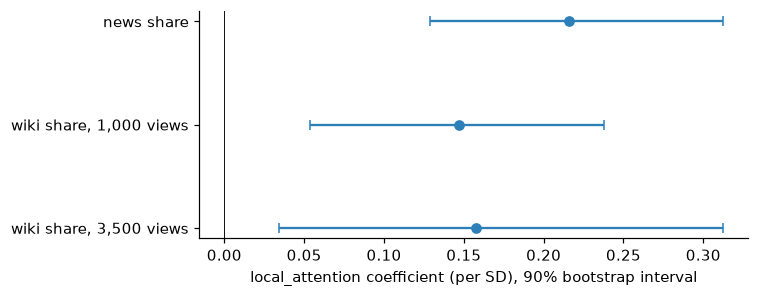

Other coefficients for covered jurors only, with and without local attention, against the full fit:


In [25]:
la = pd.read_csv(R/'jury_local_attention.csv')
c = la[la.indicator=='local_attention'].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.errorbar(c.beta, range(len(c)), xerr=[c.beta-c.boot_lo90, c.boot_hi90-c.beta], fmt='o', capsize=3, color='#2c7fb8')
ax.axvline(0, color='black', lw=.6); ax.set_yticks(range(len(c)), [s.split(':')[0] for s in c.spec]); ax.set_xlabel('local_attention coefficient (per SD), 90% bootstrap interval'); plt.tight_layout(); plt.show()
print('Other coefficients for covered jurors only, with and without local attention, against the full fit:')
fmt(la[la.indicator.isin(['home','confed','league'])][['spec','indicator','beta','boot_lo90','boot_hi90']].set_index(['spec','indicator']), 2)

## 8. Betting-odds baseline (supplement)

Seven captures qualify (before T1 and within 60 days, or between T1 and the deadline). The market is only compared with the model, never used as an input. Log-likelihoods are of the actual order restricted to the quoted players. **n is tiny: read each row, do not pool.** The 2024 and 2025 `t1_to_deadline` captures come after T1, so the market already knows more than the T1 model does.

In [26]:
od = pd.read_csv(R/'odds_baseline.csv')
show = od[['edition','captured_at','capture_phase','days_before_t1','n_quoted','market_favourite','actual_winner','favourite_is_winner',
           'model_pick_all_30','model_pick_is_winner','market_loglik_per_voted','model_loglik_per_voted','model_minus_market_per_voted']]
print(f"Market favourite won in {od.favourite_is_winner.sum()} of {len(od)} captures; M1's held-out pick won in {od.model_pick_is_winner.sum()} of {len(od)}.")
print(f"Market had the better restricted log-likelihood in {(od.model_minus_market_per_voted<0).sum()} of {len(od)} captures.")
fmt(show.set_index(['edition','captured_at']), 3)

Market favourite won in 3 of 7 captures; M1's held-out pick won in 4 of 7.
Market had the better restricted log-likelihood in 5 of 7 captures.


## 9. Robustness runs R1-R9 (supplement)

Headline model M1 re-run under one change at a time. `delta` is against base M1 on the same folds. In R1-R4 the changed run also trains on fewer editions, so the delta mixes training volume with the change. R9 (a main effect of format) cannot change a Plackett-Luce fit and matches M1 exactly.

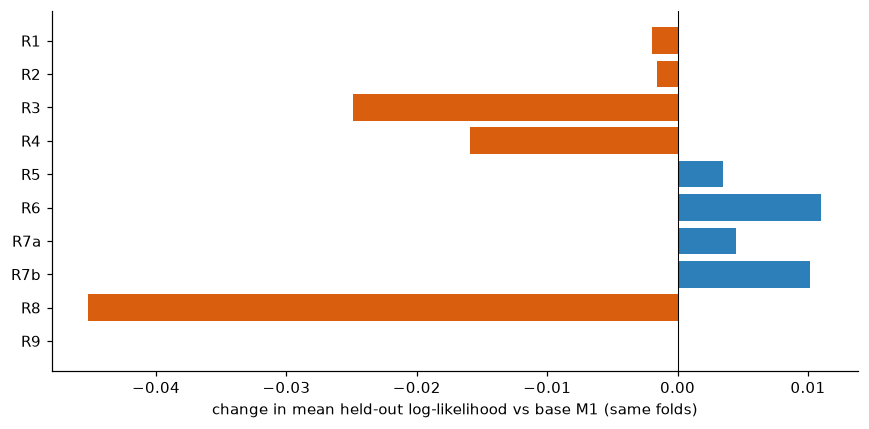

,description,n_folds,mean_ll,base_mean_ll_same_folds,delta_ll_vs_base,mean_winner_rank,mean_ndcg10
run,,,,,,,
R1,"Season editions only (2022-2025), v2 features",4,-2.277,-2.275,-0.002,2.500,0.885
R2,"Drop 2016 (3-pick ballot, half-covered fame baseline)",8,-2.317,-2.315,-0.002,2.250,0.866
R3,"Calendar editions only (2016-2021), five folds",5,-2.431,-2.406,-0.025,2.000,0.867
R4,2021-2025 with xG (npxG + xA instead of npG + A in F1),5,-2.341,-2.325,-0.016,1.800,0.887
R5,Without ratings (F2),9,-2.344,-2.348,0.003,2.222,0.876
R6,Add EA rating (z of ea_overall_t1),9,-2.337,-2.348,0.011,1.889,0.893
R7a,Without market value (F12),9,-2.343,-2.348,0.005,2.000,0.894
R7b,league_poty instead of league_player_of_season in F11,9,-2.338,-2.348,0.010,1.889,0.890
R8,"Without fame and attention (F9, F10)",9,-2.393,-2.348,-0.045,1.889,0.868


In [27]:
rb = pd.read_csv(R/'robustness.csv')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(rb.run[::-1], rb.delta_ll_vs_base[::-1], color=np.where(rb.delta_ll_vs_base[::-1]>=0, '#2c7fb8', '#d95f0e'))
ax.axvline(0, color='black', lw=.7); ax.set_xlabel('change in mean held-out log-likelihood vs base M1 (same folds)'); plt.tight_layout(); plt.show()
fmt(rb[['run','description','n_folds','mean_ll','base_mean_ll_same_folds','delta_ll_vs_base','mean_winner_rank','mean_ndcg10']].set_index('run'))

**What each run says about 2026** (utilities only, before the juror simulation; none of this changed any decision). The order of the top four moves with the specification:

In [28]:
pd.set_option('display.max_colwidth', 120)
rb[['run','top5_2026','top5_overlap_with_base','top10_overlap_with_base','spearman_with_base_2026','same_top_pick_as_base']].set_index('run')

,top5_2026,top5_overlap_with_base,top10_overlap_with_base,spearman_with_base_2026,same_top_pick_as_base
run,,,,,
R1,Ousmane Dembélé (19%); Kylian Mbappé (16%); Lamine Yamal (13%); Lionel Messi (10%); Harry Kane (8%),4,8,0.969744,False
R2,Kylian Mbappé (22%); Lionel Messi (19%); Lamine Yamal (13%); Ousmane Dembélé (11%); Harry Kane (5%),4,9,0.995996,False
R3,Lionel Messi (26%); Kylian Mbappé (24%); Lamine Yamal (13%); Ousmane Dembélé (6%); Khvicha Kvaratskhelia (4%),5,9,0.969299,True
R4,Lamine Yamal (16%); Kylian Mbappé (15%); Ousmane Dembélé (15%); Lionel Messi (11%); Harry Kane (6%),4,9,0.979088,False
R5,Kylian Mbappé (22%); Lionel Messi (22%); Lamine Yamal (12%); Ousmane Dembélé (10%); Khvicha Kvaratskhelia (4%),5,10,0.994216,False
R6,Kylian Mbappé (23%); Lionel Messi (19%); Ousmane Dembélé (12%); Lamine Yamal (11%); Harry Kane (5%),4,10,0.984427,False
R7a,Lionel Messi (28%); Kylian Mbappé (20%); Lamine Yamal (12%); Ousmane Dembélé (9%); Harry Kane (4%),4,10,0.992881,True
R7b,Kylian Mbappé (32%); Lionel Messi (21%); Lamine Yamal (14%); Ousmane Dembélé (8%); Harry Kane (3%),4,10,0.993326,False
R8,Kylian Mbappé (21%); Ousmane Dembélé (17%); Lionel Messi (10%); Lamine Yamal (9%); Khvicha Kvaratskhelia (7%),5,8,0.953726,False


## 10. The 2026 forecast (locked as git tag `forecast-v2`)

Final M1 fit on all nine labelled editions, then 10,000 simulated ballots on the real 2026 jury (100 nations, 10 picks), with home/confederation/league effects from the 2022-2025 ballots and the link between model strengths and juror utilities re-estimated on nine editions. **This is a forecast only; no 2026 result has been used or added to the repository.**

In [29]:
f = pd.read_csv(R/'forecast_2026_v2_T1.csv', comment='#')
cols = ['forecast_rank','player_name','nationality','p_win','p_top3','p_top10','expected_rank','rank_p10','rank_p90','expected_points']
fmt(f[cols].head(12).set_index('forecast_rank'), 3)

,player_name,nationality,p_win,p_top3,p_top10,expected_rank,rank_p10,rank_p90,expected_points
forecast_rank,,,,,,,,,
1,Lionel Messi,Argentina,0.311,0.658,0.960,3.449,1.000,7.000,902.717
2,Kylian Mbappé,France,0.288,0.653,0.958,3.518,1.000,8.000,890.783
3,Lamine Yamal,Spain,0.159,0.485,0.917,4.736,1.000,10.000,733.960
4,Ousmane Dembélé,France,0.111,0.385,0.863,5.787,1.000,12.000,631.980
5,Khvicha Kvaratskhelia,Georgia,0.025,0.139,0.651,9.390,3.000,18.000,369.378
6,Harry Kane,England,0.029,0.148,0.639,9.563,3.000,18.000,368.855
7,Achraf Hakimi,Morocco,0.019,0.103,0.580,10.443,3.000,20.000,314.500
8,Michael Olise,France,0.014,0.093,0.551,10.931,4.000,21.000,299.657
9,Rodri,Spain,0.015,0.083,0.521,11.320,4.000,21.000,279.156


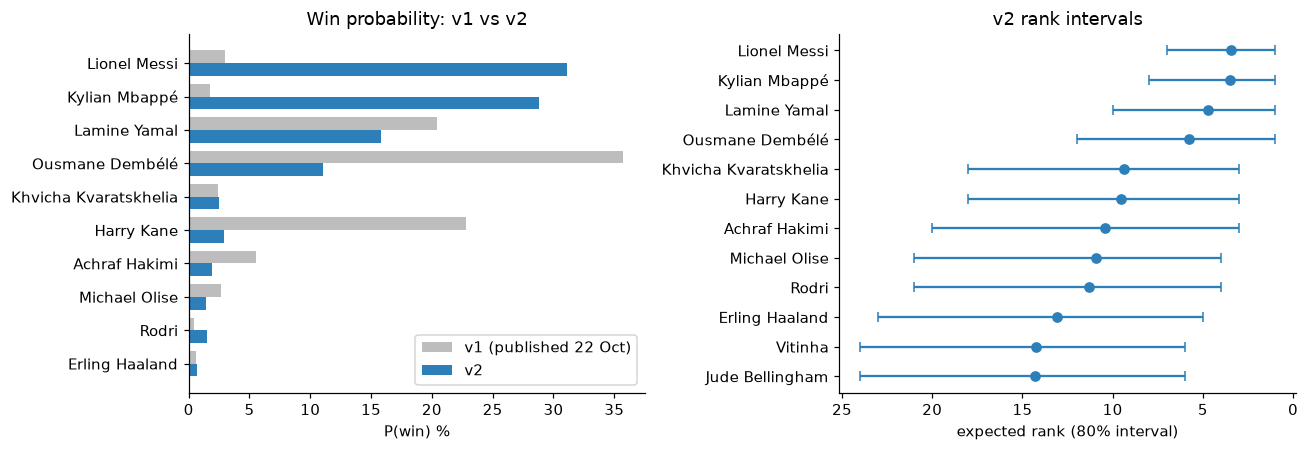

,p_win_v1,p_win_v2,forecast_rank_v1,forecast_rank_v2
player_name,,,,
Lionel Messi,0.030,0.311,7,1
Kylian Mbappé,0.018,0.288,9,2
Lamine Yamal,0.204,0.159,3,3
Ousmane Dembélé,0.357,0.111,1,4
Khvicha Kvaratskhelia,0.024,0.025,6,5
Harry Kane,0.228,0.029,2,6
Achraf Hakimi,0.055,0.019,4,7
Michael Olise,0.026,0.014,5,8
Rodri,0.004,0.015,12,9


In [30]:
v = pd.read_csv(R/'forecast_2026_v2_vs_v1.csv').head(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
y = np.arange(len(v))[::-1]; h = .38
axes[0].barh(y+h/2, v.p_win_v1*100, h, color='#bdbdbd', label='v1 (published 22 Oct)')
axes[0].barh(y-h/2, v.p_win_v2*100, h, color='#2c7fb8', label='v2')
axes[0].set_yticks(y, v.player_name); axes[0].set_xlabel('P(win) %'); axes[0].legend(); axes[0].set_title('Win probability: v1 vs v2')
top = f.head(12).iloc[::-1]
axes[1].errorbar(top.expected_rank, range(len(top)), xerr=[top.expected_rank-top.rank_p10, top.rank_p90-top.expected_rank], fmt='o', capsize=3, color='#2c7fb8')
axes[1].set_yticks(range(len(top)), top.player_name); axes[1].invert_xaxis(); axes[1].set_xlabel('expected rank (80% interval)'); axes[1].set_title('v2 rank intervals')
plt.tight_layout(); plt.show()
fmt(v[['player_name','p_win_v1','p_win_v2','forecast_rank_v1','forecast_rank_v2']].set_index('player_name'), 3)

**Why:** the final M1 coefficients with 90% intervals. Individual awards and fame carry the most weight.

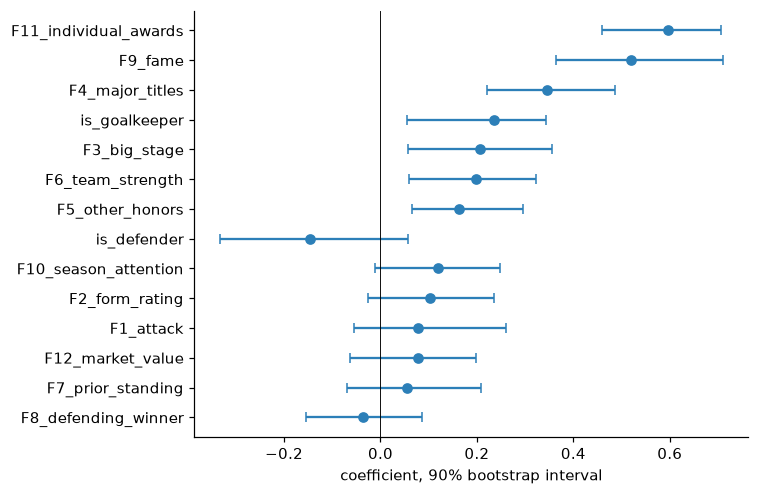

In [31]:
c = pd.read_csv(R/'coefficients_M1.csv', comment='#').sort_values('beta', key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.6)); d = c.iloc[::-1]
ax.errorbar(d.beta, range(len(d)), xerr=[d.beta-d.bootstrap_lo90, d.bootstrap_hi90-d.beta], fmt='o', capsize=3, color='#2c7fb8')
ax.axvline(0, color='black', lw=.6); ax.set_yticks(range(len(d)), d.feature); ax.set_xlabel('coefficient, 90% bootstrap interval'); plt.tight_layout(); plt.show()

In [32]:
print(open(R/'explanations_2026_v2.md').read())

# Why the v2 model ranks 2026 this way (T1, M1)

<!-- sha256_t1=e9a441c640650300771a2e115e0656355f72e05c108c98707c11b1c7eaf612ca -->
<!-- git_commit=cfcbca8 -->
<!-- model=M1 (ten-edition PL, v2 features) -->
<!-- seed=7 n_simulations=10000 n_bootstrap=500 -->

These are the model's arithmetic, not causes. Every feature is a within-edition z-score, so a contribution is measured against the average 2026 nominee. Nothing here is used to tune or change the model.

- **#1 Lionel Messi**: utility +2.92 (plain first-pick probability 24.4%). Pushing up: individual awards (player of the year, golden ball, ...) (+1.90); baseline fame (pre-season Wikipedia attention) (+1.45); match ratings (+0.23). Pulling down: major titles (UCL / World Cup / continental) (-0.29); team strength (club rating, UCL and tournament stage) (-0.27); season attention beyond what performance explains (-0.15).
- **#2 Kylian Mbappé**: utility +2.80 (plain first-pick probability 21.5%). Pushing up: individual awards (playe

**Link and sensitivity.** The link slope and shared SD barely move when the ballot strengths come from one pooled fit; the forecast is also stable to the bias source and to 5 absent jurors.

In [33]:
display(fmt(pd.read_csv(R/'juror_link_v2.csv').set_index('alpha_source'), 3))
s = pd.read_csv(R/'forecast_2026_v2_sensitivity.csv', comment='#').head(6)
fmt(s[['player_name','p_win','p_win_pooled_bias','p_win_95_jurors','expected_rank','expected_rank_pooled_bias','expected_rank_95_jurors']].set_index('player_name'), 3)

,bias_source,k,sigma_shared,r2_within_edition,n_player_editions,b_home,b_confed,b_league
alpha_source,,,,,,,,
own jury era (main),2022-2025 fit,1.347,1.631,0.558,270,2.311,0.366,0.478
pooled nine-edition fit (sensitivity),pooled 2016-2025 fit,1.346,1.633,0.557,270,2.470,0.509,0.269


,p_win,p_win_pooled_bias,p_win_95_jurors,expected_rank,expected_rank_pooled_bias,expected_rank_95_jurors
player_name,,,,,,
Lionel Messi,0.311,0.301,0.301,3.449,3.506,3.546
Kylian Mbappé,0.288,0.292,0.294,3.518,3.510,3.488
Lamine Yamal,0.159,0.161,0.161,4.736,4.725,4.729
Ousmane Dembélé,0.111,0.113,0.110,5.787,5.778,5.730
Khvicha Kvaratskhelia,0.025,0.026,0.028,9.390,9.368,9.460
Harry Kane,0.029,0.030,0.028,9.563,9.545,9.562


## What is next
Stage 6 stopped here by design: the next step (spec 9.3) needs `data/holdout/bdo_2026_result.csv` (rank 1-30, points if published). Once it is added, the comparison of v2 against v1 and the market, and the check of the named misses (Rodri, Haaland, Mbappe, Hakimi, Vitinha), can be run; then the paper figures and tables (spec section 11).